# Flow Matching on Lie Groups: reproducing the paper and comparing with regression

**Paper:** Finn M. Sherry and Bart M. N. Smets, *Flow Matching on Lie Groups* (2025), [arXiv:2504.00494](https://arxiv.org/abs/2504.00494).  
**Author implementation:** https://github.com/finnsherry/FlowMatching

**What this notebook does**
1. Implement left-trivialized conditional flow matching on **SE(2)**, **SO(3)**, and **SE(2) × ℝ²**.
2. Check the group operations and the paper's exact conditional velocity identities.
3. Train time-dependent MLP velocity fields (four hidden layers, width 64) and generate samples by Lie-group ODE integration.
4. Re-create the **qualitative experiment families** in paper Figures 1–3: line → line, line → circle, and a product-group example.
5. Train an ordinary **one-step supervised regression** baseline on the very same independent start/end pairs, so we can compare *learning the conditional mean* with *learning a transport flow*.

> **Reproduction fidelity:** The paper specifies the formulae, groups, architecture size, and qualitative datasets, but not all training hyperparameters or numerical distribution parameters. The synthetic samplers, optimizer, and integration settings below are **explicit approximations**, not claimed to be bitwise-identical to the authors' experiments. To match their implementation exactly, use the author's `experiments/` notebooks. This notebook is deliberately self-contained and easy to adapt to `obscalib` or another geometry library. No downloaded training data is required.

**Requirements:** Python ≥3.10, `torch`, `numpy`, `matplotlib`, `IPython`. CPU and CUDA supported; no external network or project path required. Run cells sequentially.

## 0. The precise difference from ordinary regression

Given **independent** samples $G_0\sim p_0$, $G_1\sim p_1$ and a uniformly random $t\in[0,1]$, define

$$
\xi = \log(G_0^{-1}G_1), \qquad G_t = G_0\exp(t\xi).
$$

The paper's left-trivialized **conditional** velocity target is

$$
\underbrace{u_t(G_t\mid G_1)}_{\text{Lie algebra coordinates}}
= \frac{\log(G_t^{-1}G_1)}{1-t}
=\xi .
$$

We learn a time-dependent field $v_\theta(G_t,t)$ using a simple MSE:

$$
\mathcal L_{\mathrm{CFM}}=\mathbb{E}_{G_0,G_1,t}\,\|v_\theta(G_t,t)-\xi\|^2.
$$

**Training:** compute $(G_t,\xi)$ analytically, evaluate the neural network once, backpropagate. **No ODE simulation in the training loop.**

**Generation:** draw new $G_0\sim p_0$, then integrate the learned ODE via

$$
\dot G_t = (L_{G_t})_*v_\theta(G_t,t), \quad
G_{t+\Delta t}\approx G_t\exp\!\big(\Delta t\,v_\theta(G_t,t)\big).
$$

Ordinary direct regression instead predicts a **single endpoint update** $\hat\xi_\theta(G_0)$ from $G_0$ and minimizes $\|\hat\xi_\theta(G_0)-\log(G_0^{-1}G_1)\|^2$. For *independent* start/end pairs it estimates a conditional mean; it cannot generally express multimodal $p_1$. This is a **deliberately unfavorable setup for direct regression**, which should not be confused with your usual *paired, conditioned* calibration-update regression: when each sensor observation determines a unique target, a direct regressor can be excellent.

*Important:* The paper is **unconditional generation**. There is no sensor encoder, calibration prior, or conditional posterior in these experiments. We will discuss how to add those later.

In [27]:
import os
import math
import random
from dataclasses import dataclass
from pathlib import Path

import numpy as np
import torch
from torch import nn
import torch.nn.functional as F
import matplotlib.pyplot as plt
from IPython.display import display

SEED = 42
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)
DEVICE = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
DTYPE = torch.float32

# Default is an interactive tutorial. Switch to False for more complete training.
QUICK_MODE = False
SMOKE_TEST = os.environ.get('LIE_FM_SMOKE_TEST', '0') == '1'
TRAIN_STEPS = 12 if SMOKE_TEST else (650 if QUICK_MODE else 3000)
BATCH_SIZE = 48 if SMOKE_TEST else (256 if QUICK_MODE else 512)
BASELINE_STEPS = 12 if SMOKE_TEST else (650 if QUICK_MODE else 1500)
EVAL_SAMPLES = 48 if SMOKE_TEST else 256
ODE_STEPS = 8 if SMOKE_TEST else (36 if QUICK_MODE else 72)
LEARNING_RATE = 1e-3
PLOT_EVERYTHING = not SMOKE_TEST
SAVE_FIGURES = False
OUTPUT_DIR = Path('lie_fm_figures')

# Turn individual figures / groups off if you only want one experiment.
RUN_CASES = {
    'se2_line_to_line': True,
    'se2_line_to_circle': True,
    'so3_line_to_line': True,
    'so3_line_to_circle': True,
    'se2_times_r2': True,
}

# Limit CPU thread oversubscription for tiny MLPs; adapt to your machine.
if DEVICE.type == 'cpu':
    torch.set_num_threads(min(torch.get_num_threads(), 4))
print(f'Device: {DEVICE}, PyTorch: {torch.__version__}, quick={QUICK_MODE}, steps={TRAIN_STEPS}, batch={BATCH_SIZE}')

Device: cuda, PyTorch: 2.7.1+cu126, quick=False, steps=3000, batch=512


## 1. Geometry interface

Each group exposes `mul`, `inv`, `exp`, `log`, `encode`, and `dim`. The neural network predicts **algebra coordinates**, not an unconstrained group matrix. Multiplication/exponentiation enforce geometric validity at every generation step.

For **SE(2)**, group elements are `[x, y, theta]`; their Lie algebra is `[vx, vy, omega]`. The exponential/logarithm implement the translation–rotation coupling (paper Eqs. 10–12), rather than treating angular motion as ordinary Euclidean coordinates. For **SO(3)**, group elements are rotation matrices and the algebra is a 3-vector rotation-vector coordinate. A quaternion-based matrix logarithm remains stable near $180^\circ$.

All operations use torch tensors; you can swap this section for your repository's `SE2`/`SO3` implementation **without changing training/inference** if the interface and shapes match.

In [28]:
PI = math.pi


def wrap_angle(angle):
    return torch.remainder(angle + PI, 2 * PI) - PI


def sinc_unscaled(x):
    return torch.sinc(x / PI)  # torch.sinc(y) = sin(pi*y) / (pi*y), including zero


class SE2Group:
    dim = 3
    name = 'SE(2)'

    def mul(self, a, b):
        c, s = a[..., 2].cos(), a[..., 2].sin()
        x = a[..., 0] + c * b[..., 0] - s * b[..., 1]
        y = a[..., 1] + s * b[..., 0] + c * b[..., 1]
        return torch.stack((x, y, wrap_angle(a[..., 2] + b[..., 2])), dim=-1)

    def inv(self, a):
        c, s = a[..., 2].cos(), a[..., 2].sin()
        x = -c * a[..., 0] - s * a[..., 1]
        y = s * a[..., 0] - c * a[..., 1]
        return torch.stack((x, y, wrap_angle(-a[..., 2])), dim=-1)

    def exp(self, xi):
        h = xi[..., 2] / 2
        scale, c, s = sinc_unscaled(h), h.cos(), h.sin()
        x = scale * (c * xi[..., 0] - s * xi[..., 1])
        y = scale * (s * xi[..., 0] + c * xi[..., 1])
        return torch.stack((x, y, wrap_angle(xi[..., 2])), dim=-1)

    def log(self, a):
        h = wrap_angle(a[..., 2]) / 2
        inv_scale, c, s = 1 / sinc_unscaled(h).clamp_min(1e-6), h.cos(), h.sin()
        vx = inv_scale * (c * a[..., 0] + s * a[..., 1])
        vy = inv_scale * (-s * a[..., 0] + c * a[..., 1])
        return torch.stack((vx, vy, 2 * h), dim=-1)

    def encode(self, a):
        return torch.cat((a[..., :2], a[..., 2:3].cos(), a[..., 2:3].sin()), dim=-1)

    def identity(self, n, device=DEVICE):
        return torch.zeros(n, 3, device=device, dtype=DTYPE)


class SO3Group:
    dim = 3
    name = 'SO(3)'

    def mul(self, a, b):
        return a @ b

    def inv(self, a):
        return a.transpose(-1, -2)

    @staticmethod
    def hat(w):
        x, y, z = w.unbind(-1)
        O = torch.zeros_like(x)
        return torch.stack((O, -z, y, z, O, -x, -y, x, O), dim=-1).reshape(w.shape[:-1] + (3, 3))

    def exp(self, w):
        theta2 = (w * w).sum(dim=-1, keepdim=True)
        theta = theta2.sqrt()
        A = torch.where(theta2 < 1e-6, 1 - theta2 / 6 + theta2 * theta2 / 120, theta.sin() / theta.clamp_min(1e-8))
        B = torch.where(theta2 < 1e-6, 0.5 - theta2 / 24 + theta2 * theta2 / 720, (1 - theta.cos()) / theta2.clamp_min(1e-8))
        W = self.hat(w)
        I = torch.eye(3, dtype=w.dtype, device=w.device).expand(w.shape[:-1] + (3, 3))
        return I + A[..., None] * W + B[..., None] * (W @ W)

    def log(self, R):
        # Stable matrix -> unit quaternion using the largest component branch.
        # q = (w,x,y,z); avoids division by sin(angle) near angle = pi.
        m00, m11, m22 = R[..., 0, 0], R[..., 1, 1], R[..., 2, 2]
        q_abs = torch.sqrt(torch.clamp(torch.stack((1 + m00 + m11 + m22, 1 + m00 - m11 - m22, 1 - m00 + m11 - m22, 1 - m00 - m11 + m22), dim=-1), min=0))
        r01, r02, r10, r12, r20, r21 = R[..., 0, 1], R[..., 0, 2], R[..., 1, 0], R[..., 1, 2], R[..., 2, 0], R[..., 2, 1]
        q0 = torch.stack((q_abs[..., 0] ** 2, r21 - r12, r02 - r20, r10 - r01), dim=-1)
        q1 = torch.stack((r21 - r12, q_abs[..., 1] ** 2, r10 + r01, r02 + r20), dim=-1)
        q2 = torch.stack((r02 - r20, r10 + r01, q_abs[..., 2] ** 2, r12 + r21), dim=-1)
        q3 = torch.stack((r10 - r01, r02 + r20, r12 + r21, q_abs[..., 3] ** 2), dim=-1)
        candidates = torch.stack((q0, q1, q2, q3), dim=-2) / (2 * q_abs.clamp_min(1e-4))[..., :, None]
        best = q_abs.argmax(dim=-1)
        q = torch.gather(candidates, dim=-2, index=best[..., None, None].expand(*best.shape, 1, 4)).squeeze(-2)
        q = F.normalize(q, dim=-1)
        q = torch.where(q[..., :1] < 0, -q, q)  # shortest-axis representative
        xyz_norm = torch.linalg.vector_norm(q[..., 1:], dim=-1, keepdim=True)
        angle = 2 * torch.atan2(xyz_norm, q[..., :1])
        scale = torch.where(xyz_norm < 1e-7, 2 / q[..., :1].clamp_min(1e-7), angle / xyz_norm.clamp_min(1e-7))
        return scale * q[..., 1:]

    def encode(self, R):
        return R.reshape(*R.shape[:-2], 9)

    def identity(self, n, device=DEVICE):
        return torch.eye(3, device=device, dtype=DTYPE).expand(n, 3, 3).clone()


class SE2TimesR2Group:
    dim = 5
    name = 'SE(2) x R^2'

    def __init__(self):
        self.se2 = SE2Group()

    def mul(self, a, b):
        return torch.cat((self.se2.mul(a[..., :3], b[..., :3]), a[..., 3:] + b[..., 3:]), dim=-1)

    def inv(self, a):
        return torch.cat((self.se2.inv(a[..., :3]), -a[..., 3:]), dim=-1)

    def exp(self, xi):
        return torch.cat((self.se2.exp(xi[..., :3]), xi[..., 3:]), dim=-1)

    def log(self, a):
        return torch.cat((self.se2.log(a[..., :3]), a[..., 3:]), dim=-1)

    def encode(self, a):
        return torch.cat((self.se2.encode(a[..., :3]), a[..., 3:]), dim=-1)

    def identity(self, n, device=DEVICE):
        return torch.zeros(n, 5, device=device, dtype=DTYPE)


GROUPS = {'se2': SE2Group(), 'so3': SO3Group(), 'product': SE2TimesR2Group()}

### Unit checks: this is worth doing before learning anything

In particular, a rotation close to $\pi$ should satisfy `exp(log(R)) ≈ R` even though the rotation vector may jump sign at the logarithm branch cut. We test the **group element** rather than incorrectly comparing unwrapped coordinates.

In [29]:
@torch.no_grad()
def geometry_smoke_tests():
    se2, so3, prod = GROUPS['se2'], GROUPS['so3'], GROUPS['product']
    gen = torch.Generator(device='cpu').manual_seed(123)
    for group in (se2, so3, prod):
        xi = torch.randn(256, group.dim, generator=gen, dtype=DTYPE).to(DEVICE) * 0.7
        if group is so3:
            axis = F.normalize(torch.randn(64, 3, generator=gen).to(DEVICE), dim=-1)
            xi[:64] = axis * (PI - 1e-4)
        element = group.exp(xi)
        reconstructed = group.exp(group.log(element))
        max_exp_log = (reconstructed - element).abs().max().item()
        identity_error = (group.mul(group.inv(element), element) - group.identity(len(xi))).abs().max().item()
        assert max_exp_log < 1e-3, (group.name, 'exp(log)', max_exp_log)
        assert identity_error < 1e-3, (group.name, 'inverse', identity_error)
        print(f'{group.name:15s} exp(log(g)) max error: {max_exp_log:.2e} | inverse max error: {identity_error:.2e}')

geometry_smoke_tests()

SE(2)           exp(log(g)) max error: 2.38e-07 | inverse max error: 3.58e-07
SO(3)           exp(log(g)) max error: 4.77e-07 | inverse max error: 5.96e-07
SE(2) x R^2     exp(log(g)) max error: 2.38e-07 | inverse max error: 4.77e-07


## 2. Synthetic distributions for Figures 1–3

The published figures show **two** SE(2) experiments (horizontal→vertical line and vertical line→circle), **two** SO(3) experiments (lines and a spherical circle), and **one** SE(2)×ℝ² experiment. We reproduce those five **qualitative tasks** and their source/middle/target layout. The exact numerical noise/range/orientation choices below are ours.

Both endpoints are drawn **independently** at each iteration: the training data are distributions, *not* matched pairs. This detail is the key to understanding why FM can do something that naïve endpoint regression cannot.

In [30]:
@dataclass(frozen=True)
class Experiment:
    name: str
    group_key: str
    caption: str


EXPERIMENTS = {
    'se2_line_to_line': Experiment('se2_line_to_line', 'se2', 'Figure 1 top: horizontal line -> vertical line'),
    'se2_line_to_circle': Experiment('se2_line_to_circle', 'se2', 'Figure 1 bottom: vertical line -> circle'),
    'so3_line_to_line': Experiment('so3_line_to_line', 'so3', 'Figure 2 top: line -> line on sphere'),
    'so3_line_to_circle': Experiment('so3_line_to_circle', 'so3', 'Figure 2 bottom: line -> circle on sphere'),
    'se2_times_r2': Experiment('se2_times_r2', 'product', 'Figure 3: SE(2) line->circle and R^2 blob->ring'),
}


def uniform(n, lo, hi, device=DEVICE):
    return lo + (hi - lo) * torch.rand(n, device=device, dtype=DTYPE)


def sample_se2_geometry(n, shape, device=DEVICE):
    noise = 0.025 * torch.randn(n, device=device, dtype=DTYPE)
    a = uniform(n, -1.0, 1.0, device)
    if shape == 'horizontal':
        return torch.stack((a, -0.85 + noise, 0.05 * torch.randn_like(a)), dim=-1)
    if shape == 'vertical':
        return torch.stack((0.85 + noise, a, (PI / 2) + 0.05 * torch.randn_like(a)), dim=-1)
    if shape == 'left_vertical':
        return torch.stack((-0.85 + noise, a, (PI / 2) + 0.05 * torch.randn_like(a)), dim=-1)
    if shape == 'circle':
        angle = uniform(n, -PI, PI, device)
        radius = 0.79 + 0.025 * torch.randn_like(angle)
        return torch.stack((0.2 + radius * angle.cos(), radius * angle.sin(), wrap_angle(angle + PI / 2)), dim=-1)
    raise ValueError(shape)


def xyz_to_rotation(n, azimuth, polar, roll, device=DEVICE):
    so3 = GROUPS['so3']
    a = torch.zeros(n, 3, device=device, dtype=DTYPE)
    b, c = a.clone(), a.clone()
    a[:, 2] = azimuth
    b[:, 1] = polar
    c[:, 2] = roll
    return so3.mul(so3.mul(so3.exp(a), so3.exp(b)), so3.exp(c))


def sample_so3_geometry(n, shape, device=DEVICE):
    noise = 0.025 * torch.randn(n, device=device, dtype=DTYPE)
    if shape == 'horizontal':
        azimuth = uniform(n, -0.85, 0.85, device)
        polar = 1.20 + noise
        roll = torch.zeros_like(polar)
    elif shape == 'vertical':
        azimuth = 0.65 + noise
        polar = uniform(n, 0.55, 2.20, device)
        roll = torch.full_like(polar, PI / 2)
    elif shape == 'circle':
        azimuth = uniform(n, -PI, PI, device)
        polar = 1.20 + noise
        roll = torch.full_like(polar, PI / 2)
    else:
        raise ValueError(shape)
    return xyz_to_rotation(n, azimuth, polar, roll, device)


def sample_distribution(experiment, endpoint, n, device=DEVICE):
    assert endpoint in (0, 1)
    case = experiment.name if isinstance(experiment, Experiment) else experiment
    if case == 'se2_line_to_line':
        return sample_se2_geometry(n, 'horizontal' if endpoint == 0 else 'vertical', device)
    if case == 'se2_line_to_circle':
        return sample_se2_geometry(n, 'left_vertical' if endpoint == 0 else 'circle', device)
    if case == 'so3_line_to_line':
        return sample_so3_geometry(n, 'horizontal' if endpoint == 0 else 'vertical', device)
    if case == 'so3_line_to_circle':
        return sample_so3_geometry(n, 'vertical' if endpoint == 0 else 'circle', device)
    if case == 'se2_times_r2':
        se2 = sample_se2_geometry(n, 'left_vertical' if endpoint == 0 else 'circle', device)
        if endpoint == 0:
            z = 0.3 * torch.randn(n, 2, dtype=DTYPE, device=device)
        else:
            angle = uniform(n, -PI, PI, device)
            r = 0.90 + 0.05 * torch.randn(n, dtype=DTYPE, device=device)
            z = torch.stack((r * angle.cos(), r * angle.sin()), dim=-1)
        return torch.cat((se2, z), dim=-1)
    raise ValueError(case)


for experiment in EXPERIMENTS.values():
    group = GROUPS[experiment.group_key]
    x0, x1 = sample_distribution(experiment, 0, 8), sample_distribution(experiment, 1, 8)
    expected_shape = (8, 3, 3) if experiment.group_key == 'so3' else (8, group.dim)
    assert x0.shape == x1.shape == expected_shape, (experiment.name, x0.shape)
    print(f'{experiment.name:20s}: X0 and X1 shapes: {tuple(x0.shape)}')

se2_line_to_line    : X0 and X1 shapes: (8, 3)
se2_line_to_circle  : X0 and X1 shapes: (8, 3)
so3_line_to_line    : X0 and X1 shapes: (8, 3, 3)
so3_line_to_circle  : X0 and X1 shapes: (8, 3, 3)
se2_times_r2        : X0 and X1 shapes: (8, 5)


## 3. Flow-matching training targets: equation (7) and equation (8)

We explicitly compute the interpolation and velocity target. In the exact conditional path, the left-trivialized velocity equals the *same* $\xi$ at every time $t$. This is why the training loop does not require numerical integration. A useful check computes the velocity both ways and compares them.

In [31]:
@torch.no_grad()
def conditional_flow_batch(group, g0, g1, time=None):
    batch_size = len(g0)
    if time is None:
        time = torch.rand(batch_size, 1, device=g0.device, dtype=DTYPE)
    xi = group.log(group.mul(group.inv(g0), g1))
    gt = group.mul(g0, group.exp(time * xi))
    return gt, time, xi


@torch.no_grad()
def verify_conditional_velocity():
    for name in ('se2_line_to_circle', 'so3_line_to_circle', 'se2_times_r2'):
        experiment = EXPERIMENTS[name]
        group = GROUPS[experiment.group_key]
        g0 = sample_distribution(experiment, 0, 256)
        g1 = sample_distribution(experiment, 1, 256)
        time = uniform(256, 0.02, 0.98)[:, None]
        gt, time, xi = conditional_flow_batch(group, g0, g1, time)
        conditional_xi = group.log(group.mul(group.inv(gt), g1)) / (1 - time)
        error = (conditional_xi - xi).abs().max().item()
        reconstructed = group.mul(g0, group.exp(xi))
        endpoint_error = (reconstructed - g1).abs().max().item()
        print(f'{name:22s} | conditional velocity max err={error:.2e} | endpoint group max err={endpoint_error:.2e}')
        assert error < 2e-3 and endpoint_error < 2e-3

verify_conditional_velocity()

se2_line_to_circle     | conditional velocity max err=1.30e-05 | endpoint group max err=4.77e-07
so3_line_to_circle     | conditional velocity max err=7.15e-06 | endpoint group max err=5.66e-07
se2_times_r2           | conditional velocity max err=1.30e-05 | endpoint group max err=8.34e-07


## 4. Neural vector field and the CFM loss

The paper uses an **MLP with four hidden layers of 64 neurons**; we use `SiLU` activations (an unspecified choice in the text). The network receives $(G_t,t)$ and returns `dim(G)` *left-trivialized Lie algebra coordinates*, so there is no extra constraint-enforcement loss or matrix projection.

In [32]:
class VelocityMLP(nn.Module):
    def __init__(self, group, hidden_dim=64, hidden_layers=4):
        super().__init__()
        self.group = group
        # Query at identity is only used to derive the encoded input dimension.
        sample_encoding_dim = group.encode(group.identity(1, device='cpu')).shape[-1]
        modules = []
        last_dim = sample_encoding_dim + 1
        for _ in range(hidden_layers):
            modules += [nn.Linear(last_dim, hidden_dim), nn.SiLU()]
            last_dim = hidden_dim
        modules += [nn.Linear(last_dim, group.dim)]
        self.net = nn.Sequential(*modules)

    def forward(self, element, time):
        if time.ndim == 0:
            time = time.expand(len(element), 1)
        elif time.ndim == 1:
            time = time[:, None]
        features = torch.cat((self.group.encode(element), time), dim=-1)
        return self.net(features)


def flow_matching_loss(model, group, g0, g1):
    with torch.no_grad():
        gt, t, target_velocity = conditional_flow_batch(group, g0, g1)
    predicted_velocity = model(gt, t)
    return F.mse_loss(predicted_velocity, target_velocity)


def fit_flow_model(experiment, steps=TRAIN_STEPS, batch_size=BATCH_SIZE, lr=LEARNING_RATE, verbose=True):
    group = GROUPS[experiment.group_key]
    model = VelocityMLP(group).to(DEVICE)
    optimizer = torch.optim.Adam(model.parameters(), lr=lr)
    history = []
    model.train()
    for step in range(steps):
        g0 = sample_distribution(experiment, 0, batch_size)
        g1 = sample_distribution(experiment, 1, batch_size)
        optimizer.zero_grad(set_to_none=True)
        loss = flow_matching_loss(model, group, g0, g1)
        loss.backward()
        optimizer.step()
        history.append(float(loss.detach()))
        if verbose and (step == 0 or (step + 1) % max(steps // 4, 1) == 0):
            print(f'  step {step + 1:4}/{steps} | CFM loss {history[-1]:.4f}')
    model.eval()
    return model, np.asarray(history)


# Reconfirm that even with matrix SO(3) states, the network produces a 3-vector.
with torch.no_grad():
    for group in GROUPS.values():
        model = VelocityMLP(group).to(DEVICE)
        y = model(group.identity(4), torch.full((4, 1), 0.5, device=DEVICE))
        assert y.shape == (4, group.dim)
        print(f'{group.name:15s} vector-field output shape: {tuple(y.shape)}')

SE(2)           vector-field output shape: (4, 3)
SO(3)           vector-field output shape: (4, 3)
SE(2) x R^2     vector-field output shape: (4, 5)


## 5. Integration at inference: Lie-Euler and Lie-midpoint

Here **we really solve an ODE**, but only after training. Each step is a group multiplication by an exponential, ensuring the trajectory stays on the group. Midpoint usually improves accuracy with the same time-step size at the expense of twice as many network calls.

In [33]:
@torch.no_grad()
def generate_trajectory(model, group, start, steps=ODE_STEPS, method='midpoint', record_steps=None):
    assert method in ('euler', 'midpoint')
    dt = 1.0 / steps
    element = start.clone()
    trajectory = [(0.0, element.detach().clone())]
    selected = set(record_steps) if record_steps is not None else set(range(steps + 1))
    for k in range(steps):
        t = k * dt
        time = torch.full((len(element), 1), t, dtype=DTYPE, device=element.device)
        v0 = model(element, time)
        if method == 'euler':
            v = v0
        else:
            mid = group.mul(element, group.exp((dt / 2) * v0))
            v = model(mid, time + dt / 2)
        element = group.mul(element, group.exp(dt * v))
        if k + 1 in selected:
            trajectory.append(((k + 1) * dt, element.detach().clone()))
    return trajectory


@torch.no_grad()
def generate_samples(model, group, start, steps=ODE_STEPS, method='midpoint'):
    return generate_trajectory(model, group, start, steps=steps, method=method, record_steps={steps})[-1][1]


# Exact conditional velocities must integrate to exactly the target for both groups as steps -> inf.
@torch.no_grad()
def check_integrator():
    for group in GROUPS.values():
        xi = torch.tensor([[0.2, -0.4, 0.7] + ([0.3, -0.2] if group.dim == 5 else [])], dtype=DTYPE, device=DEVICE)
        start = group.identity(1)
        class ConstantField(nn.Module):
            def forward(self, element, time):
                return xi.expand(len(element), -1)
        expected = group.mul(start, group.exp(xi))
        predicted = generate_samples(ConstantField(), group, start, steps=5)
        err = (predicted - expected).abs().max().item()
        print(f'{group.name:15s} constant-field exact integration error: {err:.2e}')
        assert err < 1e-5

check_integrator()

SE(2)           constant-field exact integration error: 4.77e-07
SO(3)           constant-field exact integration error: 2.98e-07
SE(2) x R^2     constant-field exact integration error: 4.77e-07


## 6. Figures: source / transported points / target

For SE(2), each sample is an arrow on the plane. For SO(3), the position is $R\,e_z$ on the unit sphere and its orientation is the tangent direction $R\,e_x$. We plot several integration snapshots with color indicating time, similarly to paper Figures 1–3.

In [34]:
def to_numpy(x):
    return x.detach().cpu().numpy()


def draw_se2_arrows(ax, poses, color='tab:blue', opacity=0.9, scale=0.18, width=0.005, size_limit=140):
    poses = to_numpy(poses[:size_limit])
    ax.quiver(poses[:, 0], poses[:, 1], np.cos(poses[:, 2]), np.sin(poses[:, 2]), angles='xy', scale_units='xy', scale=1 / scale, width=width, color=color, alpha=opacity)
    ax.set_aspect('equal')
    ax.set_xlim(-1.50, 1.50)
    ax.set_ylim(-1.50, 1.50)
    ax.grid(True, alpha=0.18)
    ax.set_xlabel('x')
    ax.set_ylabel('y')


def draw_r2(ax, vectors, color='tab:blue', opacity=0.9):
    v = to_numpy(vectors)
    ax.scatter(v[:, 0], v[:, 1], c=[color] if isinstance(color, str) else color, s=17, alpha=opacity)
    ax.set_aspect('equal')
    ax.set_xlim(-1.5, 1.5)
    ax.set_ylim(-1.5, 1.5)
    ax.grid(True, alpha=0.2)


def setup_sphere(ax):
    azimuth = np.linspace(-np.pi, np.pi, 28)
    polar = np.linspace(0, np.pi, 15)
    xs = np.outer(np.cos(azimuth), np.sin(polar))
    ys = np.outer(np.sin(azimuth), np.sin(polar))
    zs = np.outer(np.ones_like(azimuth), np.cos(polar))
    ax.plot_wireframe(xs, ys, zs, color='silver', alpha=0.4, linewidth=0.4)
    ax.set(xlim=(-1.2, 1.2), ylim=(-1.2, 1.2), zlim=(-1.2, 1.2))
    ax.set_box_aspect((1, 1, 1))
    ax.view_init(elev=23, azim=-54)
    ax.set_xlabel('x', labelpad=-6)
    ax.set_ylabel('y', labelpad=-6)
    ax.set_zlabel('z', labelpad=-6)


def draw_so3_arrows(ax, rotations, color='tab:blue', opacity=0.9, size_limit=90):
    r = to_numpy(rotations[:size_limit])
    pos = r[:, :, 2]
    tangent = r[:, :, 0]
    ax.scatter(pos[:, 0], pos[:, 1], pos[:, 2], color=color, alpha=opacity, s=7)
    ax.quiver(pos[:, 0], pos[:, 1], pos[:, 2], tangent[:, 0], tangent[:, 1], tangent[:, 2], length=0.17, normalize=True, color=color, alpha=opacity, linewidth=0.65)


def plot_experiment(experiment, model, num_samples=EVAL_SAMPLES, integration_steps=ODE_STEPS):
    group = GROUPS[experiment.group_key]
    start = sample_distribution(experiment, 0, num_samples)
    target = sample_distribution(experiment, 1, num_samples)
    selected = {max(1, round(integration_steps * p)) for p in (0.2, 0.4, 0.6, 0.8, 1.0)}
    flow = generate_trajectory(model, group, start, steps=integration_steps, record_steps=selected)
    cmap = plt.get_cmap('coolwarm')

    if experiment.group_key == 'so3':
        fig = plt.figure(figsize=(13, 4.3))
        axes = [fig.add_subplot(1, 3, i, projection='3d') for i in (1, 2, 3)]
        for ax in axes:
            setup_sphere(ax)
        draw_so3_arrows(axes[0], start)
        draw_so3_arrows(axes[2], target)
        for t, point in flow:
            draw_so3_arrows(axes[1], point, color=cmap(t), opacity=0.5 if t < 1 else 0.95, size_limit=64)
    else:
        rows = 2 if experiment.group_key == 'product' else 1
        fig, axs = plt.subplots(rows, 3, figsize=(12, rows * 3.7), squeeze=False)
        axes = list(axs[0])
        draw_se2_arrows(axes[0], start[..., :3])
        draw_se2_arrows(axes[2], target[..., :3])
        for t, point in flow:
            draw_se2_arrows(axes[1], point[..., :3], color=cmap(t), opacity=0.35 if t < 1 else 0.95)
        if rows == 2:
            draw_r2(axs[1, 0], start[..., 3:])
            draw_r2(axs[1, 2], target[..., 3:])
            for t, point in flow:
                draw_r2(axs[1, 1], point[..., 3:], color=cmap(t), opacity=0.3 if t < 1 else 0.95)
            axs[1, 0].set_ylabel('ℝ² component')

    for ax, title in zip(axes, ('X0 (prior)', 'learned flow, t∈[0,1]', 'X1 (target)')):
        ax.set_title(title)
    fig.suptitle(experiment.caption, fontweight='semibold')
    fig.tight_layout()
    if SAVE_FIGURES:
        OUTPUT_DIR.mkdir(exist_ok=True, parents=True)
        fig.savefig(OUTPUT_DIR / f'{experiment.name}.png', dpi=160, bbox_inches='tight')
    plt.show()
    return start, flow[-1][1], target

## 7. Train and evaluate all experiments

Use `QUICK_MODE=True` for a **practical learning exercise** (650 Adam steps per experiment). Change to `QUICK_MODE=False` and rerun configuration and training cells for substantially longer convergence. Training has randomness and can take longer on CPU; the reported values are those **actually obtained by this run**, not copied from the paper.

Qualitative agreement with the figures matters more than a tiny training loss here, because the conditional velocity is not a deterministic function of $(G_t,t)$ when independently sampled paths cross. We also compute **RBF-MMD on embedded group coordinates**, which is a heuristic distribution-distance diagnostic, not a metric reported by the paper.

In [35]:
@torch.no_grad()
def squared_mmd(a, b, max_points=256):
    # Biased RBF MMD estimator; use embeddings with Euclidean chord distance.
    a, b = a[:max_points], b[:max_points]
    pooled = torch.cat((a, b), dim=0)
    distances = torch.cdist(pooled, pooled).square()
    positive = distances[distances > 1e-10]
    bandwidth2 = positive.median().clamp_min(1e-5) if len(positive) else torch.tensor(1.0, device=a.device)
    kaa = torch.exp(-torch.cdist(a, a).square() / (2 * bandwidth2))
    kbb = torch.exp(-torch.cdist(b, b).square() / (2 * bandwidth2))
    kab = torch.exp(-torch.cdist(a, b).square() / (2 * bandwidth2))
    return (kaa.mean() + kbb.mean() - 2 * kab.mean()).item()


models, histories, evaluations = {}, {}, {}
for case, enabled in RUN_CASES.items():
    if not enabled:
        continue
    experiment = EXPERIMENTS[case]
    group = GROUPS[experiment.group_key]
    print(f'\n=== {experiment.caption} ===')
    model, history = fit_flow_model(experiment)
    models[case], histories[case] = model, history
    with torch.no_grad():
        start = sample_distribution(experiment, 0, EVAL_SAMPLES)
        target = sample_distribution(experiment, 1, EVAL_SAMPLES)
        generated = generate_samples(model, group, start)
        mmd_start = squared_mmd(group.encode(start), group.encode(target))
        mmd_generated = squared_mmd(group.encode(generated), group.encode(target))
    evaluations[case] = {'MMD(X0,X1)': mmd_start, 'MMD(flow,X1)': mmd_generated, 'final_CFM_loss': float(np.mean(history[-max(1, len(history) // 10):]))}
    print(f'  Source MMD = {mmd_start:.4f} | Generated MMD = {mmd_generated:.4f}')

print('\n=== Summary (smaller MMD is better) ===')
for case, metrics in evaluations.items():
    print(f"{case:21s} | source={metrics['MMD(X0,X1)']:.4f} | flow={metrics['MMD(flow,X1)']:.4f} | CFM loss={metrics['final_CFM_loss']:.4f}")


=== Figure 1 top: horizontal line -> vertical line ===


  step    1/3000 | CFM loss 1.7211
  step  750/3000 | CFM loss 0.0419
  step 1500/3000 | CFM loss 0.0325
  step 2250/3000 | CFM loss 0.0327
  step 3000/3000 | CFM loss 0.0303
  Source MMD = 0.9012 | Generated MMD = 0.0638

=== Figure 1 bottom: vertical line -> circle ===
  step    1/3000 | CFM loss 1.9616
  step  750/3000 | CFM loss 0.0883
  step 1500/3000 | CFM loss 0.0911
  step 2250/3000 | CFM loss 0.0876
  step 3000/3000 | CFM loss 0.0763
  Source MMD = 0.4665 | Generated MMD = 0.0029

=== Figure 2 top: line -> line on sphere ===
  step    1/3000 | CFM loss 1.2102
  step  750/3000 | CFM loss 0.0231
  step 1500/3000 | CFM loss 0.0208
  step 2250/3000 | CFM loss 0.0245
  step 3000/3000 | CFM loss 0.0195
  Source MMD = 0.7845 | Generated MMD = 0.0202

=== Figure 2 bottom: line -> circle on sphere ===
  step    1/3000 | CFM loss 1.1580
  step  750/3000 | CFM loss 0.0461
  step 1500/3000 | CFM loss 0.0277
  step 2250/3000 | CFM loss 0.0257
  step 3000/3000 | CFM loss 0.0325
  Source MMD

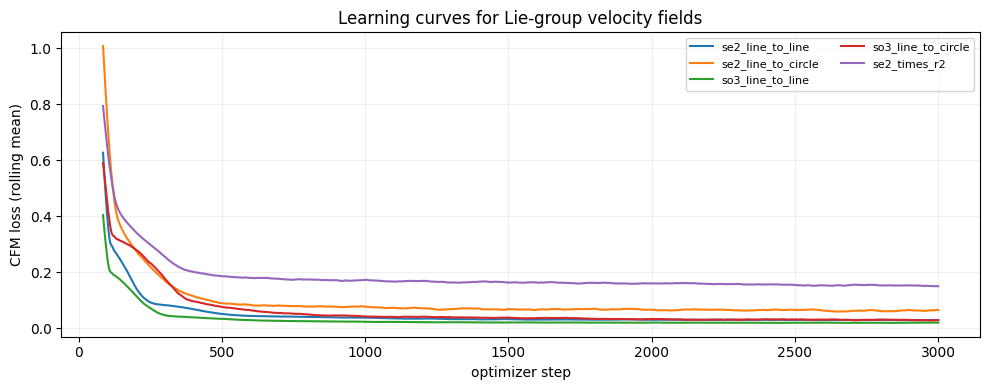

In [36]:
if histories:
    fig, ax = plt.subplots(figsize=(10, 4))
    for name, history in histories.items():
        # A smoothed curve is easier to interpret than per-minibatch variance.
        window = max(1, len(history) // 35)
        smoothed = np.convolve(history, np.ones(window) / window, mode='valid')
        ax.plot(np.arange(window, len(history) + 1), smoothed, label=name)
    ax.set(xlabel='optimizer step', ylabel='CFM loss (rolling mean)', title='Learning curves for Lie-group velocity fields')
    ax.legend(fontsize=8, ncol=2)
    ax.grid(alpha=0.2)
    fig.tight_layout()
    plt.show()

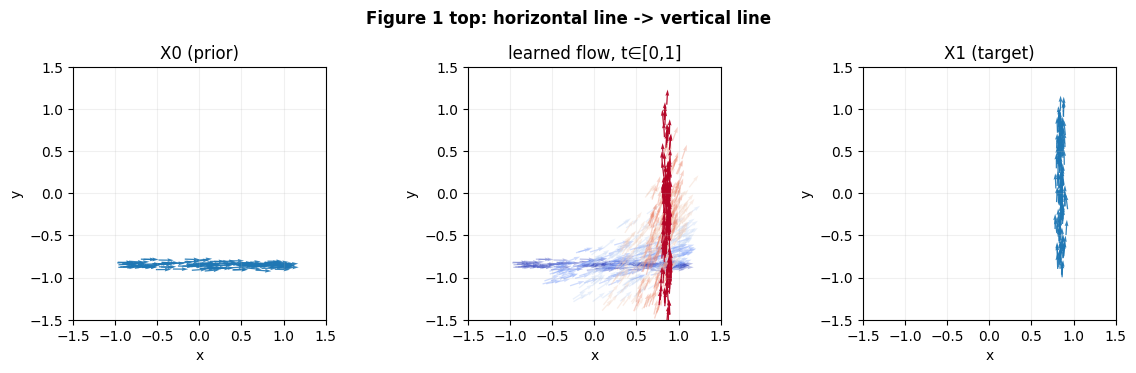

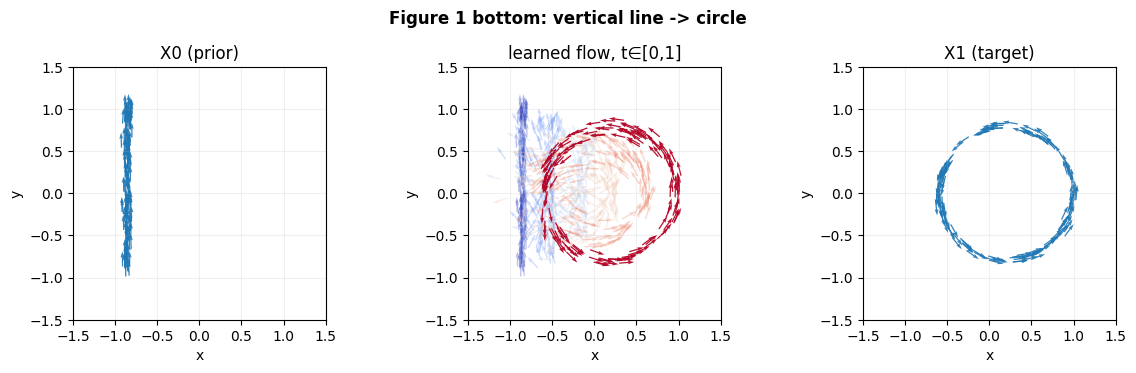

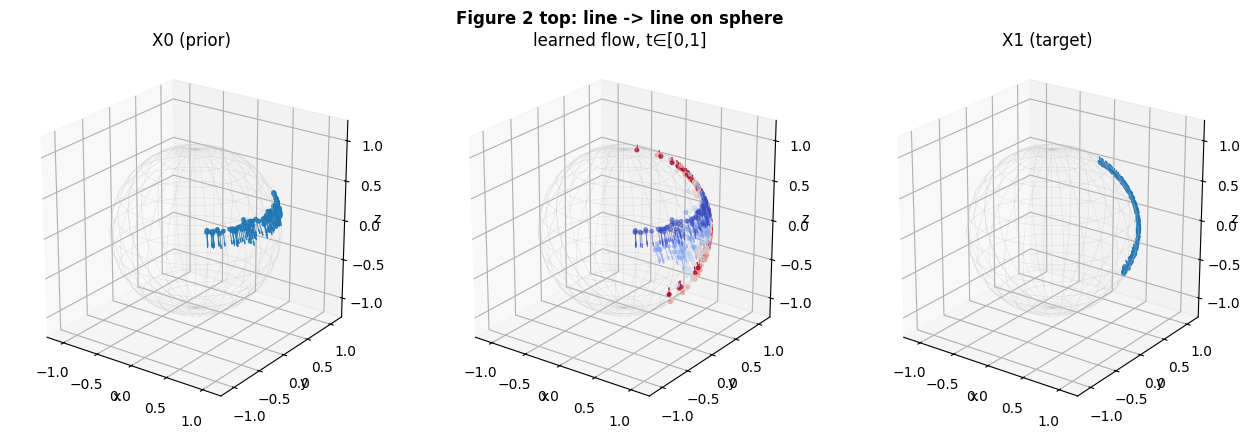

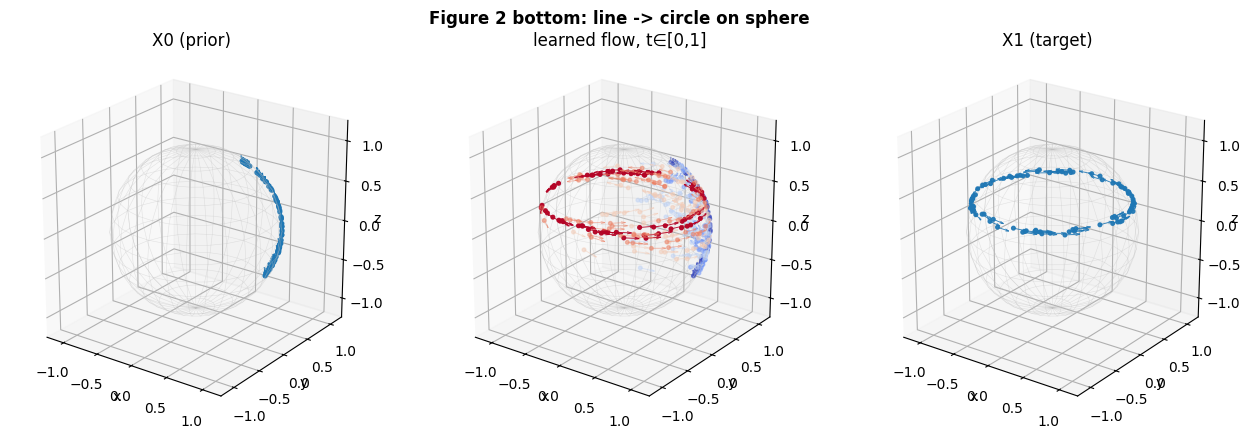

/tmp/ipykernel_2425479/306786964.py:18: UserWarning: *c* argument looks like a single numeric RGB or RGBA sequence, which should be avoided as value-mapping will have precedence in case its length matches with *x* & *y*.  Please use the *color* keyword-argument or provide a 2D array with a single row if you intend to specify the same RGB or RGBA value for all points.
  ax.scatter(v[:, 0], v[:, 1], c=[color] if isinstance(color, str) else color, s=17, alpha=opacity)


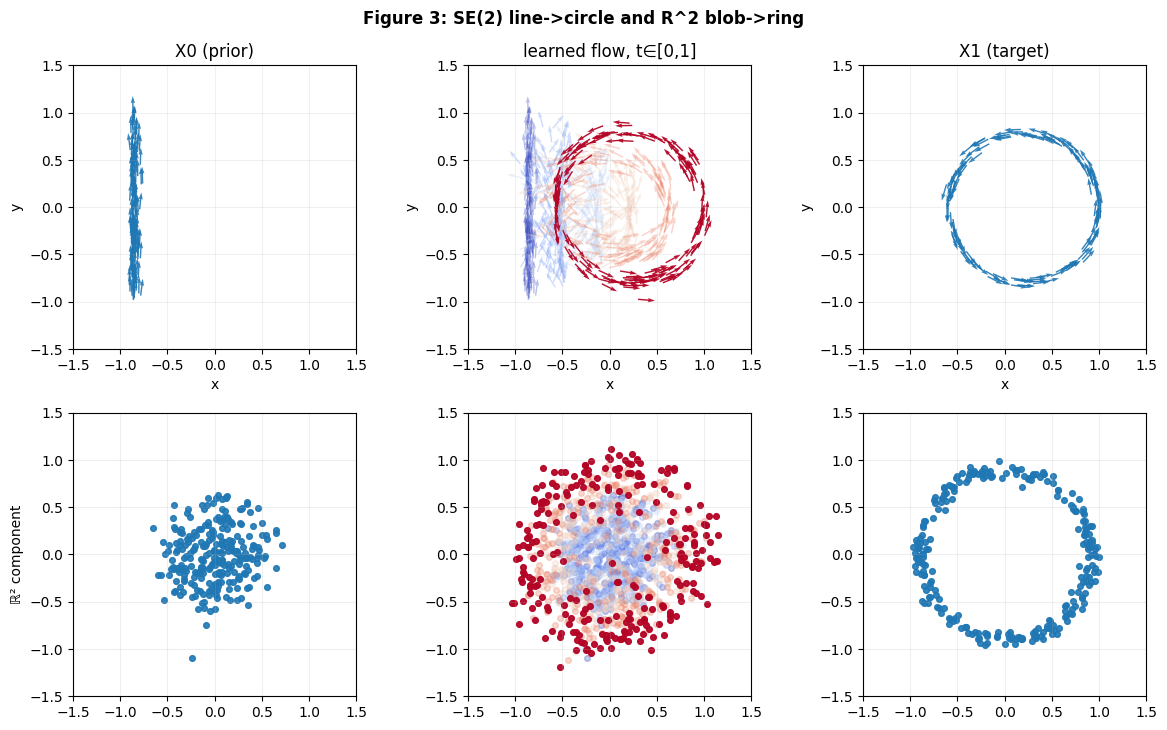

In [37]:
if PLOT_EVERYTHING:
    for case, model in models.items():
        plot_experiment(EXPERIMENTS[case], model)

## 8. Comparison: one-step endpoint regression versus FM

To isolate the **learning objective**, train a separate four-layer MLP with identical width to predict a *single* relative Lie-algebra update from each start state:

\[
\hat\xi = f_\phi(G_0), \qquad
\mathcal{L}_{\rm reg}= \mathbb{E}\|f_\phi(G_0)-\log(G_0^{-1}G_1)\|^2, \qquad
\hat G_1 = G_0\exp(\hat\xi).
\]

No time input and no integration; still geometrically valid. Because $G_1$ is **independent** of $G_0$, this baseline is *not* expected to learn the full target distribution. This comparison does **not** prove FM is always better than regression: your sensor-conditioned calibration problem has additional information unavailable in this synthetic experiment.

One-step regression vs flow on se2_line_to_circle:
  MMD(regression, target) = 0.4702
  MMD(flow, target)       = 0.0050
  Circle angle entropy [target    ] = 0.991 (1=uniform, 0=collapsed)
  Circle angle entropy [regression] = 0.569 (1=uniform, 0=collapsed)
  Circle angle entropy [flow      ] = 0.985 (1=uniform, 0=collapsed)


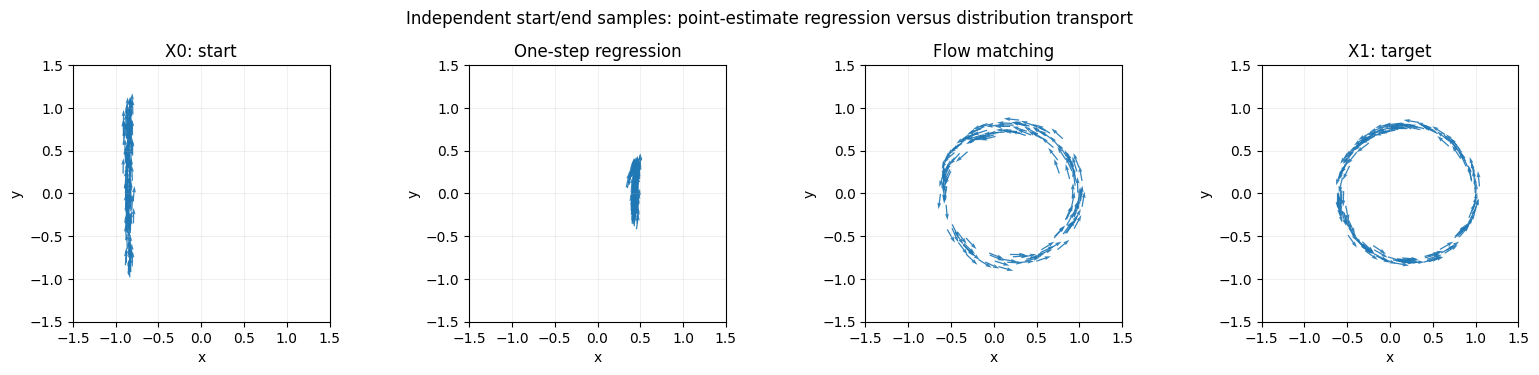

In [38]:
class DirectLieRegressor(nn.Module):
    def __init__(self, group, width=64, layers=4):
        super().__init__()
        self.group = group
        input_dim = group.encode(group.identity(1, device='cpu')).shape[-1]
        net = []
        for layer in range(layers):
            net += [nn.Linear(input_dim if layer == 0 else width, width), nn.SiLU()]
        net.append(nn.Linear(width, group.dim))
        self.net = nn.Sequential(*net)

    def forward(self, g0):
        return self.net(self.group.encode(g0))


@torch.no_grad()
def regression_generate(model, group, start):
    return group.mul(start, group.exp(model(start)))


def fit_regressor(experiment, steps=BASELINE_STEPS, batch_size=BATCH_SIZE):
    group = GROUPS[experiment.group_key]
    model = DirectLieRegressor(group).to(DEVICE)
    optimizer = torch.optim.Adam(model.parameters(), lr=LEARNING_RATE)
    losses = []
    model.train()
    for _ in range(steps):
        g0 = sample_distribution(experiment, 0, batch_size)
        g1 = sample_distribution(experiment, 1, batch_size)
        with torch.no_grad():
            delta = group.log(group.mul(group.inv(g0), g1))
        optimizer.zero_grad(set_to_none=True)
        loss = F.mse_loss(model(g0), delta)
        loss.backward()
        optimizer.step()
        losses.append(float(loss.detach()))
    model.eval()
    return model, np.asarray(losses)


COMPARE_CASE = 'se2_line_to_circle'
assert COMPARE_CASE in models, 'Enable se2_line_to_circle in RUN_CASES before this cell.'
comparison_exp = EXPERIMENTS[COMPARE_CASE]
comparison_group = GROUPS[comparison_exp.group_key]
regression_model, regression_losses = fit_regressor(comparison_exp)
with torch.no_grad():
    comparison_start = sample_distribution(comparison_exp, 0, EVAL_SAMPLES)
    comparison_target = sample_distribution(comparison_exp, 1, EVAL_SAMPLES)
    comparison_regression = regression_generate(regression_model, comparison_group, comparison_start)
    comparison_fm = generate_samples(models[COMPARE_CASE], comparison_group, comparison_start)
    comparison_reg_mmd = squared_mmd(comparison_group.encode(comparison_regression), comparison_group.encode(comparison_target))
    comparison_fm_mmd = squared_mmd(comparison_group.encode(comparison_fm), comparison_group.encode(comparison_target))

print(f'One-step regression vs flow on {COMPARE_CASE}:')
print(f'  MMD(regression, target) = {comparison_reg_mmd:.4f}')
print(f'  MMD(flow, target)       = {comparison_fm_mmd:.4f}')

# Bonus: on this *known synthetic circle*, angular coverage is an intuitive diversity check.
def circle_angular_entropy(states, bins=12):
    xy = to_numpy(states[:, :2])
    azimuth = np.arctan2(xy[:, 1], xy[:, 0] - 0.2)
    counts, _ = np.histogram(azimuth, bins=bins, range=(-PI, PI))
    probs = counts / max(counts.sum(), 1)
    return float(-(probs[probs > 0] * np.log(probs[probs > 0])).sum() / np.log(bins))

for label, states in [('target', comparison_target), ('regression', comparison_regression), ('flow', comparison_fm)]:
    print(f'  Circle angle entropy [{label:10s}] = {circle_angular_entropy(states):.3f} (1=uniform, 0=collapsed)')

if PLOT_EVERYTHING:
    fig, axes = plt.subplots(1, 4, figsize=(16, 3.7))
    for ax, states, title in zip(axes, (comparison_start, comparison_regression, comparison_fm, comparison_target), ('X0: start', 'One-step regression', 'Flow matching', 'X1: target')):
        draw_se2_arrows(ax, states)
        ax.set_title(title)
    fig.suptitle('Independent start/end samples: point-estimate regression versus distribution transport')
    fig.tight_layout()
    plt.show()

## 9. Sensitivity to the number of ODE integration steps

A big conceptual distinction: one-step regression needs **one model evaluation**, while a trained flow typically needs **many**. The conditional FM objective is independent of the solver discretization, but sample quality is not. Use this cell to find a sensible solver budget for later calibration experiments.

Lie-midpoint NFE = 2 x steps; lower estimated MMD is better:
  steps= 1, NFE=  2, MMD=0.0497
  steps= 2, NFE=  4, MMD=0.0366
  steps= 4, NFE=  8, MMD=0.0200
  steps= 8, NFE= 16, MMD=0.0123
  steps=16, NFE= 32, MMD=0.0081
  steps=32, NFE= 64, MMD=0.0066
  steps=64, NFE=128, MMD=0.0062


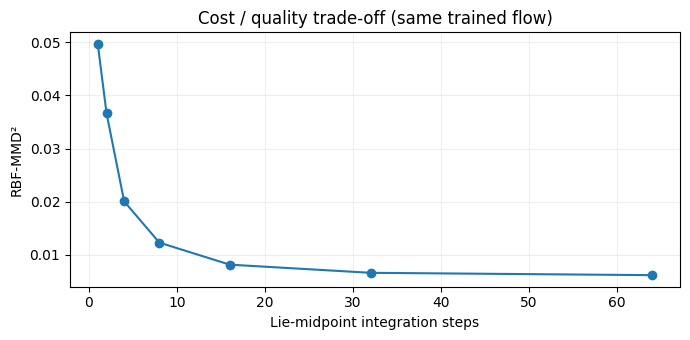

In [39]:
INTEGRATION_STEP_SWEEP = (1, 2, 4, 8, 16, 32, 64) if not SMOKE_TEST else (1, 4, 8)
if COMPARE_CASE in models:
    # Hold the source and target sample sets fixed across resolutions.
    group = GROUPS[comparison_exp.group_key]
    source = sample_distribution(comparison_exp, 0, EVAL_SAMPLES)
    target = sample_distribution(comparison_exp, 1, EVAL_SAMPLES)
    mmd_by_steps = {}
    for n_steps in INTEGRATION_STEP_SWEEP:
        predicted = generate_samples(models[COMPARE_CASE], group, source, steps=n_steps, method='midpoint')
        mmd_by_steps[n_steps] = squared_mmd(group.encode(predicted), group.encode(target))
    print('Lie-midpoint NFE = 2 x steps; lower estimated MMD is better:')
    for k, v in mmd_by_steps.items():
        print(f'  steps={k:2d}, NFE={2*k:3d}, MMD={v:.4f}')
    if PLOT_EVERYTHING:
        fig, ax = plt.subplots(figsize=(7, 3.5))
        ax.plot(list(mmd_by_steps), list(mmd_by_steps.values()), '-o')
        ax.set(xlabel='Lie-midpoint integration steps', ylabel='RBF-MMD²', title='Cost / quality trade-off (same trained flow)')
        ax.grid(alpha=0.2)
        fig.tight_layout()
        plt.show()

## 10. What to change for your **IMU + LiDAR calibration** project

This paper models **$p(G)$**. Your calibration task instead wants something like **$p(G_{\rm calib}\mid \mathrm{IMU},\mathrm{LiDAR},G_{\rm prior})$** or a conditional correction distribution $p(\Delta G\mid\cdots)$. A reasonable incremental bridge is:

1. Replace the standalone velocity MLP input by `[group_embedding(G_t), t, sensor_feature]`, where `sensor_feature` is the pooled output from your existing transformer. Keep the Lie algebra output and CFM loss.
2. Draw $G_1$ from *ground-truth calibration*, optionally centered relative to a supplied noisy prior $G_{\rm prior}$. Draw $G_0$ from a **chosen, clearly documented conditional prior**. At training time, both target and prior are known; at inference, only prior and sensors are available.
3. Compare to your existing **paired direct regression** baseline, with identical sensor encoders and train/validation splits. Unlike the toy independent regression above, this is a fair real-world comparison.
4. Report rotational geodesic error, translation error, success fraction at large initialization angles, **sample diversity / multimodality**, calibration consistency, and inference network evaluations. Include unseen-trajectory / unseen-dataset tests.
5. Only then consider flow matching on **SE(3)** or a product of several SE(3) groups. The `Group` interface keeps the rest of the training loop almost unchanged. If the target is nearly deterministic, flow sampling may not outperform an MLP regressor; its benefit would need to come from genuinely multimodal or uncertain calibration posteriors.

**Numerical caveats:** SO(3) logarithms have a branch cut at $\pi$; rotations exactly at $180^\circ$ require careful numerical handling. SE(3) additionally needs carefully chosen relative left/right update conventions and translation/rotation loss scales. For the toy SE(2) experiments, wrapping at ±π is already visible.

**Conventions:** We use **left-trivialized velocities** and right multiplication of the current group state by `exp(dt * velocity)`, as in the paper's Eq. (7). Do not accidentally substitute a space-frame/right-trivialized field from your geometry utilities.

### Pointers for exact replication

- Paper: [Flow Matching on Lie Groups](https://arxiv.org/abs/2504.00494) (equations 7–9, Figure 1–3)
- Author code, including the experiment notebooks: [finnsherry/FlowMatching](https://github.com/finnsherry/FlowMatching)
- This notebook uses independent synthetic samplers and self-contained implementations; it does not import the author's `lieflow` package.

In [40]:

class SE3Group:
    dim = 6
    name = "SE(3)"

    def __init__(self):
        self.so3 = GROUPS["so3"]

    def mul(self, a, b):
        return a @ b

    def inv(self, T):
        R = T[..., :3, :3].transpose(-1, -2)
        p = -(R @ T[..., :3, 3:4])
        upper = torch.cat((R, p), dim=-1)
        bottom = torch.zeros((*T.shape[:-2], 1, 4), device=T.device, dtype=T.dtype)
        bottom[..., 0, 3] = 1
        return torch.cat((upper, bottom), dim=-2)

    def left_jacobian(self, omega):
        theta2 = (omega * omega).sum(-1, keepdim=True)
        theta = theta2.sqrt()
        theta2_safe = theta2.clamp_min(1e-12)
        theta_safe = theta.clamp_min(1e-6)

        a = torch.where(theta2 < 1e-6, 0.5 - theta2 / 24 + theta2.square() / 720, (1 - theta.cos()) / theta2_safe)
        b = torch.where(theta2 < 1e-6, 1 / 6 - theta2 / 120 + theta2.square() / 5040, (theta - theta.sin()) / theta_safe.pow(3))

        W = self.so3.hat(omega)
        I = torch.eye(3, device=omega.device, dtype=omega.dtype).expand(*omega.shape[:-1], 3, 3)
        return I + a[..., None] * W + b[..., None] * (W @ W)

    def exp(self, xi):
        rho, omega = xi[..., :3], xi[..., 3:]
        R = self.so3.exp(omega)
        p = self.left_jacobian(omega) @ rho[..., None]

        upper = torch.cat((R, p), dim=-1)
        bottom = torch.zeros((*xi.shape[:-1], 1, 4), device=xi.device, dtype=xi.dtype)
        bottom[..., 0, 3] = 1
        return torch.cat((upper, bottom), dim=-2)

    def log(self, T):
        omega = self.so3.log(T[..., :3, :3])
        rho = torch.linalg.solve(self.left_jacobian(omega), T[..., :3, 3:4]).squeeze(-1)
        return torch.cat((rho, omega), dim=-1)

    def encode(self, T):
        return torch.cat((T[..., :3, 3], T[..., :3, :3].reshape(*T.shape[:-2], 9)), dim=-1)

    def identity(self, n, device=DEVICE):
        return torch.eye(4, device=device, dtype=DTYPE).expand(n, 4, 4).clone()


GROUPS["se3"] = SE3Group()


In [41]:

@torch.no_grad()
def verify_se3():
    group = GROUPS["se3"]
    n = 256

    xi = torch.randn(n, 6, device=DEVICE, dtype=DTYPE) * 0.4
    axis = F.normalize(torch.randn(n // 2, 3, device=DEVICE, dtype=DTYPE), dim=-1)
    xi[:n // 2, 3:] = axis * (PI - 1e-4)

    T = group.exp(xi)
    reconstructed = group.exp(group.log(T))

    inv_err = (group.mul(group.inv(T), T) - group.identity(n)).abs().max().item()
    exp_err = (reconstructed - T).abs().max().item()
    det_err = (torch.linalg.det(T[..., :3, :3]) - 1).abs().max().item()

    T0 = group.exp(torch.randn(n, 6, device=DEVICE, dtype=DTYPE) * 0.25)
    T1 = group.exp(torch.randn(n, 6, device=DEVICE, dtype=DTYPE) * 0.8)
    t = torch.rand(n, 1, device=DEVICE, dtype=DTYPE) * 0.94 + 0.03

    Tt, t, vel = conditional_flow_batch(group, T0, T1, t)
    vel_recomputed = group.log(group.mul(group.inv(Tt), T1)) / (1 - t)
    vel_err = (vel - vel_recomputed).abs().max().item()

    class ConstantField(nn.Module):
        def forward(self, element, time):
            return vel[:1].expand(len(element), -1)

    g0 = T0[:1]
    end = generate_samples(ConstantField(), group, g0, steps=24, method="midpoint")
    exact_end = group.mul(g0, group.exp(vel[:1]))
    ode_err = (end - exact_end).abs().max().item()

    print(f"SE3 max errors: exp(log)={exp_err:.2e}, inverse={inv_err:.2e}, det={det_err:.2e}, velocity={vel_err:.2e}, constant ODE={ode_err:.2e}")
    assert max(exp_err, inv_err, det_err, vel_err, ode_err) < 1e-3


verify_se3()


SE3 max errors: exp(log)=3.58e-07, inverse=5.96e-07, det=4.77e-07, velocity=1.04e-05, constant ODE=6.56e-07


In [42]:

@torch.no_grad()
def sample_se3_distribution(n, endpoint, device=DEVICE):
    group = GROUPS["se3"]

    if endpoint == 0:
        u = uniform(n, -1, 1, device)
        p = torch.stack((-0.9 + 0.03 * torch.randn_like(u), u, 0.3 * u), -1)
        yaw = torch.full_like(u, PI / 2) + 0.08 * torch.randn_like(u)
        pitch = 0.2 * u
        roll = torch.zeros_like(u)

    else:
        a = uniform(n, -PI, PI, device)
        r = 0.8 + 0.025 * torch.randn_like(a)
        p = torch.stack((0.15 + r * a.cos(), r * a.sin(), 0.35 * (2 * a).sin()), -1)
        yaw = a + PI / 2
        pitch = 0.4 * a.sin()
        roll = 0.3 * a.cos()

    wz = torch.zeros(n, 3, device=device, dtype=DTYPE)
    wy = wz.clone()
    wx = wz.clone()
    wz[:, 2], wy[:, 1], wx[:, 0] = yaw, pitch, roll

    R = group.so3.mul(group.so3.mul(group.so3.exp(wz), group.so3.exp(wy)), group.so3.exp(wx))
    T = group.identity(n, device=device)
    T[:, :3, :3], T[:, :3, 3] = R, p
    return T


EXPERIMENTS["se3_line_to_ring"] = Experiment("se3_line_to_ring", "se3", "SE(3): 3D line -> tilted, rotating wavy ring")

# Intercept the new experiment without rewriting the original samplers.
if "_sample_distribution_before_se3" not in globals():
    _sample_distribution_before_se3 = sample_distribution

def sample_distribution(experiment, endpoint, n, device=DEVICE):
    case = experiment.name if isinstance(experiment, Experiment) else experiment
    if case == "se3_line_to_ring":
        return sample_se3_distribution(n, endpoint, device)
    return _sample_distribution_before_se3(experiment, endpoint, n, device)


In [43]:

SE3_EXPERIMENT = EXPERIMENTS["se3_line_to_ring"]
SE3_STEPS = 800 if QUICK_MODE else 3000

se3_fm, se3_history = fit_flow_model(SE3_EXPERIMENT, steps=SE3_STEPS)
se3_reg, se3_reg_history = fit_regressor(SE3_EXPERIMENT, steps=SE3_STEPS)

se3_group = GROUPS["se3"]

with torch.no_grad():
    se3_start = sample_distribution(SE3_EXPERIMENT, 0, EVAL_SAMPLES)
    se3_target = sample_distribution(SE3_EXPERIMENT, 1, EVAL_SAMPLES)

    se3_fm_output = generate_samples(se3_fm, se3_group, se3_start, steps=ODE_STEPS)
    se3_reg_output = regression_generate(se3_reg, se3_group, se3_start)

    for name, sample in [("source", se3_start), ("regression", se3_reg_output), ("flow", se3_fm_output)]:
        score = squared_mmd(se3_group.encode(sample), se3_group.encode(se3_target))
        print(f"{name:12s} MMD^2 = {score:.5f}")


  step    1/3000 | CFM loss 1.0498
  step  750/3000 | CFM loss 0.0612
  step 1500/3000 | CFM loss 0.0687
  step 2250/3000 | CFM loss 0.0470
  step 3000/3000 | CFM loss 0.0425
source       MMD^2 = 0.46424
regression   MMD^2 = 0.46732
flow         MMD^2 = 0.00801


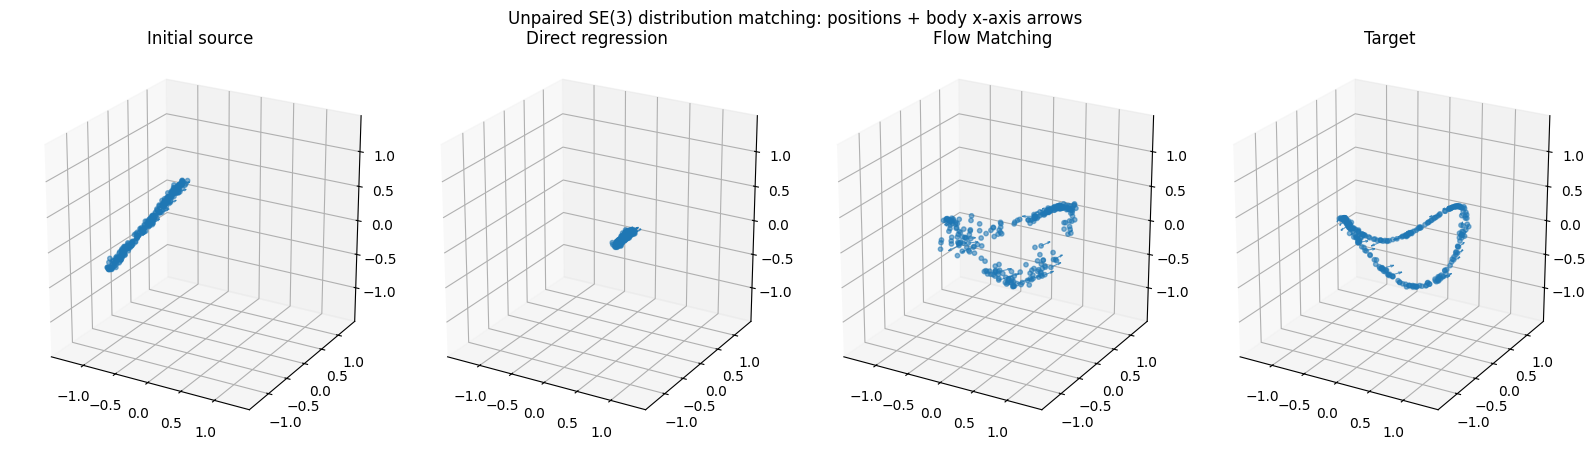

In [44]:

fig = plt.figure(figsize=(16, 4.5))

for i, (label, samples) in enumerate([
    ("Initial source", se3_start),
    ("Direct regression", se3_reg_output),
    ("Flow Matching", se3_fm_output),
    ("Target", se3_target),
], start=1):
    ax = fig.add_subplot(1, 4, i, projection="3d")
    xyz = to_numpy(samples[:, :3, 3])
    facing = to_numpy(samples[:, :3, 0])

    ax.scatter(*xyz.T, s=10, alpha=0.55)
    ax.quiver(*xyz[::8].T, *facing[::8].T, length=0.18, normalize=True, linewidth=0.8, alpha=0.7)
    ax.set(xlim=(-1.45, 1.45), ylim=(-1.45, 1.45), zlim=(-1.45, 1.45), title=label)
    ax.set_box_aspect((1, 1, 1))
    ax.view_init(elev=23, azim=-60)

fig.suptitle("Unpaired SE(3) distribution matching: positions + body x-axis arrows")
fig.tight_layout()
plt.show()


In [45]:

@torch.no_grad()
def paired_calibration_batch(n):
    group = GROUPS["se3"]

    truth_twist = torch.randn(n, 6, device=DEVICE, dtype=DTYPE) * torch.tensor([0.4, 0.4, 0.4, 0.7, 0.7, 0.7], device=DEVICE)
    truth = group.exp(truth_twist)

    observation = truth_twist + torch.randn_like(truth_twist) * torch.tensor([0.12, 0.12, 0.12, 0.18, 0.18, 0.18], device=DEVICE)

    axis = F.normalize(torch.randn(n, 3, device=DEVICE, dtype=DTYPE), dim=-1)
    angle = uniform(n, 0.0, PI - 0.01)
    perturbation = torch.cat((0.30 * torch.randn(n, 3, device=DEVICE, dtype=DTYPE), axis * angle[:, None]), dim=-1)

    prior = group.mul(truth, group.exp(perturbation))
    return prior, observation, truth


def make_se3_mlp(input_dim, hidden=64):
    layers = []
    for i in range(4):
        layers.extend([nn.Linear(input_dim if i == 0 else hidden, hidden), nn.SiLU()])
    layers.append(nn.Linear(hidden, 6))
    return nn.Sequential(*layers).to(DEVICE)


class ConditionalSE3Flow(nn.Module):
    def __init__(self):
        super().__init__()
        self.net = make_se3_mlp(12 + 12 + 6 + 1)

    def forward(self, pose, time, prior, observation):
        return self.net(torch.cat((se3_group.encode(pose), se3_group.encode(prior), observation, time), dim=-1))


class PairedSE3Regressor(nn.Module):
    def __init__(self):
        super().__init__()
        self.net = make_se3_mlp(12 + 6)

    def forward(self, prior, observation):
        return self.net(torch.cat((se3_group.encode(prior), observation), dim=-1))


paired_reg = PairedSE3Regressor().to(DEVICE)
paired_fm = ConditionalSE3Flow().to(DEVICE)

reg_optim = torch.optim.Adam(paired_reg.parameters(), lr=LEARNING_RATE)
fm_optim = torch.optim.Adam(paired_fm.parameters(), lr=LEARNING_RATE)

PAIRED_STEPS = 700 if QUICK_MODE else 2500
paired_history = {"regression": [], "flow": []}

for k in range(PAIRED_STEPS):
    prior, observation, truth = paired_calibration_batch(BATCH_SIZE)

    with torch.no_grad():
        gt_update = se3_group.log(se3_group.mul(se3_group.inv(prior), truth))
        interpolated, time, velocity = conditional_flow_batch(se3_group, prior, truth)

    reg_optim.zero_grad(set_to_none=True)
    reg_loss = F.mse_loss(paired_reg(prior, observation), gt_update)
    reg_loss.backward()
    reg_optim.step()

    fm_optim.zero_grad(set_to_none=True)
    fm_loss = F.mse_loss(paired_fm(interpolated, time, prior, observation), velocity)
    fm_loss.backward()
    fm_optim.step()

    paired_history["regression"].append(reg_loss.item())
    paired_history["flow"].append(fm_loss.item())

    if k % 200 == 0 or k + 1 == PAIRED_STEPS:
        print(f"{k + 1:4d}/{PAIRED_STEPS} regression={reg_loss.item():.4f}  flow={fm_loss.item():.4f}")

paired_reg.eval()
paired_fm.eval()


   1/2500 regression=0.6136  flow=0.6106
 201/2500 regression=0.3859  flow=0.2189
 401/2500 regression=0.2764  flow=0.1448
 601/2500 regression=0.2847  flow=0.1637
 801/2500 regression=0.2264  flow=0.1476
1001/2500 regression=0.2151  flow=0.1217
1201/2500 regression=0.1977  flow=0.1161
1401/2500 regression=0.1518  flow=0.1007
1601/2500 regression=0.1735  flow=0.1186
1801/2500 regression=0.1954  flow=0.1126
2001/2500 regression=0.1625  flow=0.1142
2201/2500 regression=0.1640  flow=0.0992
2401/2500 regression=0.1409  flow=0.0909
2500/2500 regression=0.1872  flow=0.1072


ConditionalSE3Flow(
  (net): Sequential(
    (0): Linear(in_features=31, out_features=64, bias=True)
    (1): SiLU()
    (2): Linear(in_features=64, out_features=64, bias=True)
    (3): SiLU()
    (4): Linear(in_features=64, out_features=64, bias=True)
    (5): SiLU()
    (6): Linear(in_features=64, out_features=64, bias=True)
    (7): SiLU()
    (8): Linear(in_features=64, out_features=6, bias=True)
  )
)

Large initial error subset: 166 / 512 (>=120 deg)
Uncorrected prior    | all: 0.449 m / 89.0 deg | >=120 deg: 0.426 m / 150.0 deg
Direct regression    | all: 0.287 m / 26.8 deg | >=120 deg: 0.334 m / 45.2 deg
Conditional FM       | all: 0.364 m / 32.3 deg | >=120 deg: 0.388 m / 60.3 deg


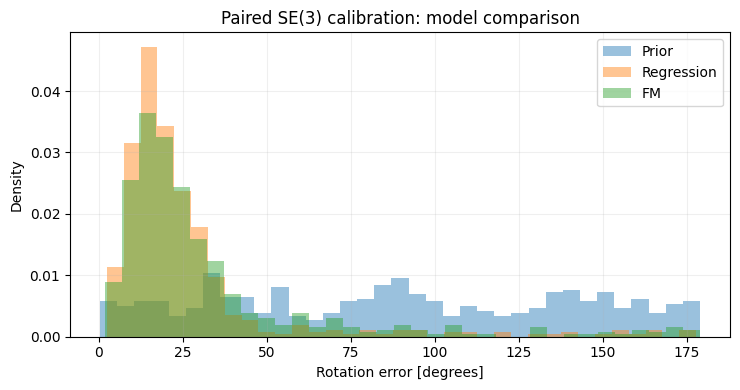

In [46]:

@torch.no_grad()
def paired_fm_inference(prior, observation, steps=ODE_STEPS):
    class ConditionedVelocity(nn.Module):
        def forward(self, pose, time):
            return paired_fm(pose, time, prior, observation)

    return generate_samples(ConditionedVelocity(), se3_group, prior, steps=steps, method="midpoint")


@torch.no_grad()
def se3_pose_errors(pred, target):
    translation_error = torch.linalg.vector_norm(pred[:, :3, 3] - target[:, :3, 3], dim=-1)
    relative_rotation = pred[:, :3, :3].transpose(-1, -2) @ target[:, :3, :3]
    rotation_error_deg = torch.rad2deg(torch.linalg.vector_norm(se3_group.so3.log(relative_rotation), dim=-1))
    return translation_error, rotation_error_deg


prior, observation, truth = paired_calibration_batch(512)

with torch.no_grad():
    corrected_reg = se3_group.mul(prior, se3_group.exp(paired_reg(prior, observation)))
    corrected_fm = paired_fm_inference(prior, observation)

    original_t, original_r = se3_pose_errors(prior, truth)
    large_angle_mask = original_r >= 120

    print(f"Large initial error subset: {large_angle_mask.sum().item()} / {len(truth)} (>=120 deg)")

    for name, predicted in [("Uncorrected prior", prior), ("Direct regression", corrected_reg), ("Conditional FM", corrected_fm)]:
        t_error, r_error = se3_pose_errors(predicted, truth)
        print(f"{name:20s} | all: {t_error.mean():.3f} m / {r_error.mean():.1f} deg | >=120 deg: {t_error[large_angle_mask].mean():.3f} m / {r_error[large_angle_mask].mean():.1f} deg")

fig, ax = plt.subplots(figsize=(7.5, 4))

for name, predicted in [("Prior", prior), ("Regression", corrected_reg), ("FM", corrected_fm)]:
    _, rotation_error = se3_pose_errors(predicted, truth)
    ax.hist(to_numpy(rotation_error), bins=35, alpha=0.45, density=True, label=name)

ax.set(xlabel="Rotation error [degrees]", ylabel="Density", title="Paired SE(3) calibration: model comparison")
ax.legend()
ax.grid(alpha=0.2)
fig.tight_layout()
plt.show()
